# 02 - Social media (tweet signal) data analysis

**Data:** `data/social/tweets_2014.json.gz`, `tweets_2015.json.gz`, `tweets_2017.json.gz` (G-CUT style release).

**What the files contain:** one JSON row per tweet with only `tweet_id`, `created_at`, `country_code`, `civil_unrest_score` and `civil_unrest_related`. **There is no tweet text.** This notebook therefore studies *signals* (volumes and classifier scores per country and day), not language.

**What the labels are:** `civil_unrest_related` is the output of a civil-unrest classifier (it is `score > 0.5`: a score of exactly 0.5 is unflagged, checked below). A "surge" is defined from a spike in these flagged tweets. It is a classifier-derived label, **not** human or ACLED ground truth.

**Inputs produced by the scripts:** `social_aggregate.py` (country-day table), `social_panel.py` (features, surge targets, splits), `social_train_baselines.py` and `social_train_sequence.py` (models).

In [1]:
import json, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
SOC = ROOT / "data" / "social_processed"
RES = ROOT / "results"
print("project root:", ROOT)

project root: /sessions/rcw-01sdgdctarhbicftt8vqc2yy/mnt/NLP


## 1. Size and coverage

In [2]:
summary = json.loads((SOC / "aggregate_summary.json").read_text(encoding="utf-8"))
print(f"tweets: {summary['total_valid_lines']:,} | malformed lines: {summary['malformed_lines']} | country-day cells: {summary['country_day_cells']:,}")
by_year = pd.DataFrame(summary["per_year"]).T
by_year["related_share"] = by_year["related"] / by_year["tweets"]
by_year

tweets: 93,435,018 | malformed lines: 0 | country-day cells: 41,422


,tweets,related,related_share
2014,27492265,1864692,0.067826
2015,35179968,3009812,0.085555
2017,30762785,3381266,0.109914


In [3]:
cd = pd.read_csv(SOC / "country_day.csv", parse_dates=["date"], keep_default_na=False, na_values=[""])
print("countries:", cd["country"].nunique(), "(note: 'NA' is Namibia and must not be read as missing)")
print("date range:", cd["date"].min().date(), "to", cd["date"].max().date())
days = cd.groupby(cd["date"].dt.year)["date"].nunique()
print("days with data per year:", days.to_dict(), "| 2016 is absent from the files")
cd["n_tweets"].describe().round(1)

countries: 42 (note: 'NA' is Namibia and must not be read as missing)
date range: 2014-01-01 to 2017-12-31
days with data per year: {2014: 361, 2015: 353, 2017: 363} | 2016 is absent from the files


count    41422.0
mean      2255.7
std       5687.8
min          1.0
25%         50.0
50%        294.0
75%       1141.0
max      49575.0
Name: n_tweets, dtype: float64

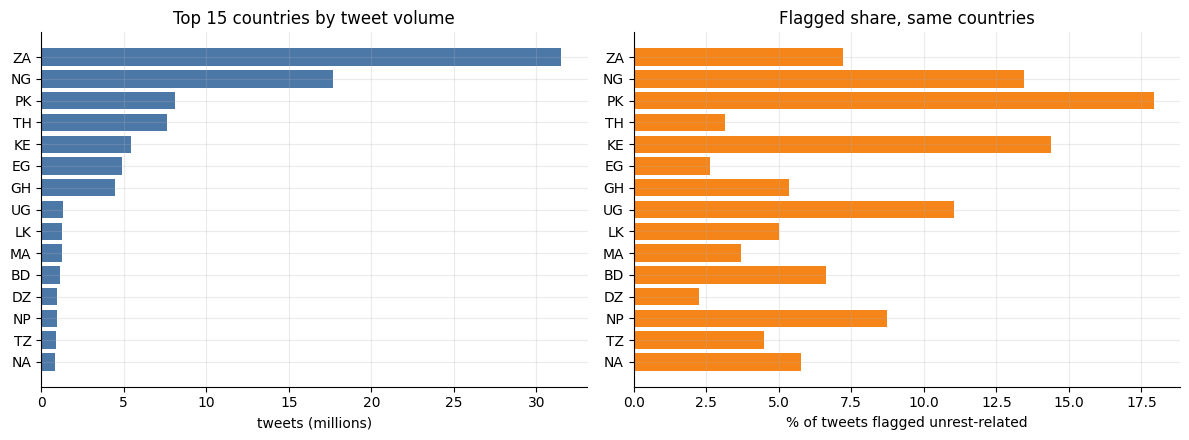

,tweets,related,related_share
ZA,31525027,2269334,0.071985
NG,17699779,2379641,0.134445
PK,8119764,1456196,0.179340
TH,7617763,239552,0.031447
KE,5451824,783664,0.143743
EG,4883269,127641,0.026138
GH,4498875,241480,0.053676
UG,1309754,144462,0.110297
LK,1260001,62991,0.049993
MA,1251914,46492,0.037137


In [4]:
pc = pd.DataFrame(summary["per_country"]).T
pc["related_share"] = pc["related"] / pc["tweets"]
pc = pc.sort_values("tweets", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
top = pc.head(15)
ax[0].barh(top.index[::-1], top["tweets"][::-1] / 1e6, color="#4c78a8")
ax[0].set_xlabel("tweets (millions)"); ax[0].set_title("Top 15 countries by tweet volume")
ax[1].barh(top.index[::-1], top["related_share"][::-1] * 100, color="#f58518")
ax[1].set_xlabel("% of tweets flagged unrest-related"); ax[1].set_title("Flagged share, same countries")
plt.tight_layout(); plt.show()
pc.head(10)

## 2. The classifier score and the flag

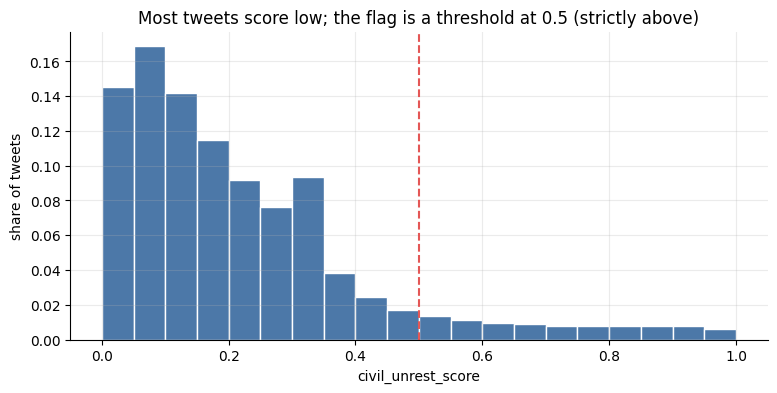

min score among flagged: 0.5000000596046448 | max score among unflagged: 0.5
flagged share overall: 0.088


In [5]:
hist = np.array(summary["score_histogram_bin_width_0.05"])
edges = np.linspace(0, 1, len(hist) + 1)
plt.bar(edges[:-1], hist / hist.sum(), width=0.05, align="edge", color="#4c78a8", edgecolor="white")
plt.axvline(0.5, color="#e45756", ls="--"); plt.xlabel("civil_unrest_score"); plt.ylabel("share of tweets")
plt.title("Most tweets score low; the flag is a threshold at 0.5 (strictly above)"); plt.show()
print("min score among flagged:", summary["min_score_among_related"], "| max score among unflagged:", summary["max_score_among_unrelated"])
print(f"flagged share overall: {by_year['related'].sum() / by_year['tweets'].sum():.3f}")

## 3. Daily signal over time

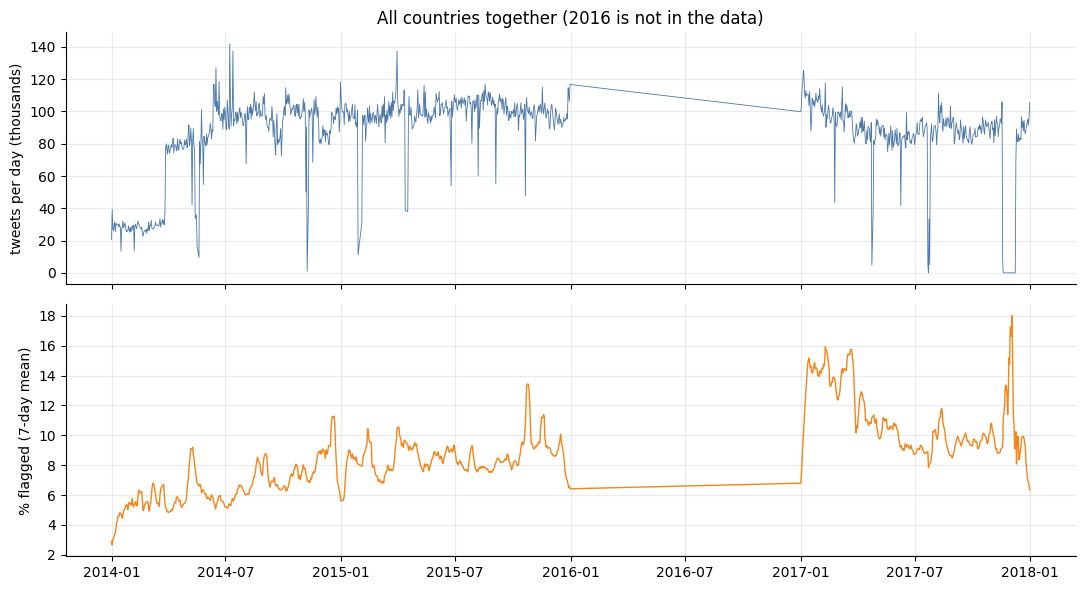

In [6]:
daily = cd.groupby("date")[["n_tweets", "n_related"]].sum()
daily["share"] = daily["n_related"] / daily["n_tweets"]
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(daily.index, daily["n_tweets"] / 1e3, lw=0.6, color="#4c78a8"); ax[0].set_ylabel("tweets per day (thousands)")
ax[1].plot(daily.index, daily["share"].rolling(7, min_periods=1).mean() * 100, lw=1, color="#f58518"); ax[1].set_ylabel("% flagged (7-day mean)")
ax[0].set_title("All countries together (2016 is not in the data)"); plt.tight_layout(); plt.show()

In [7]:
dow = cd.assign(dow=cd["date"].dt.day_name()).groupby("dow")[["n_tweets", "n_related"]].sum()
dow["share_%"] = (dow["n_related"] / dow["n_tweets"] * 100).round(2)
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow.loc[order]

,n_tweets,n_related,share_%
dow,,,
Monday,13069638,1210454,9.26
Tuesday,13500269,1280513,9.49
Wednesday,13665084,1285190,9.40
Thursday,13444702,1296352,9.64
Friday,13209375,1150418,8.71
Saturday,13096652,1005397,7.68
Sunday,13449298,1027446,7.64


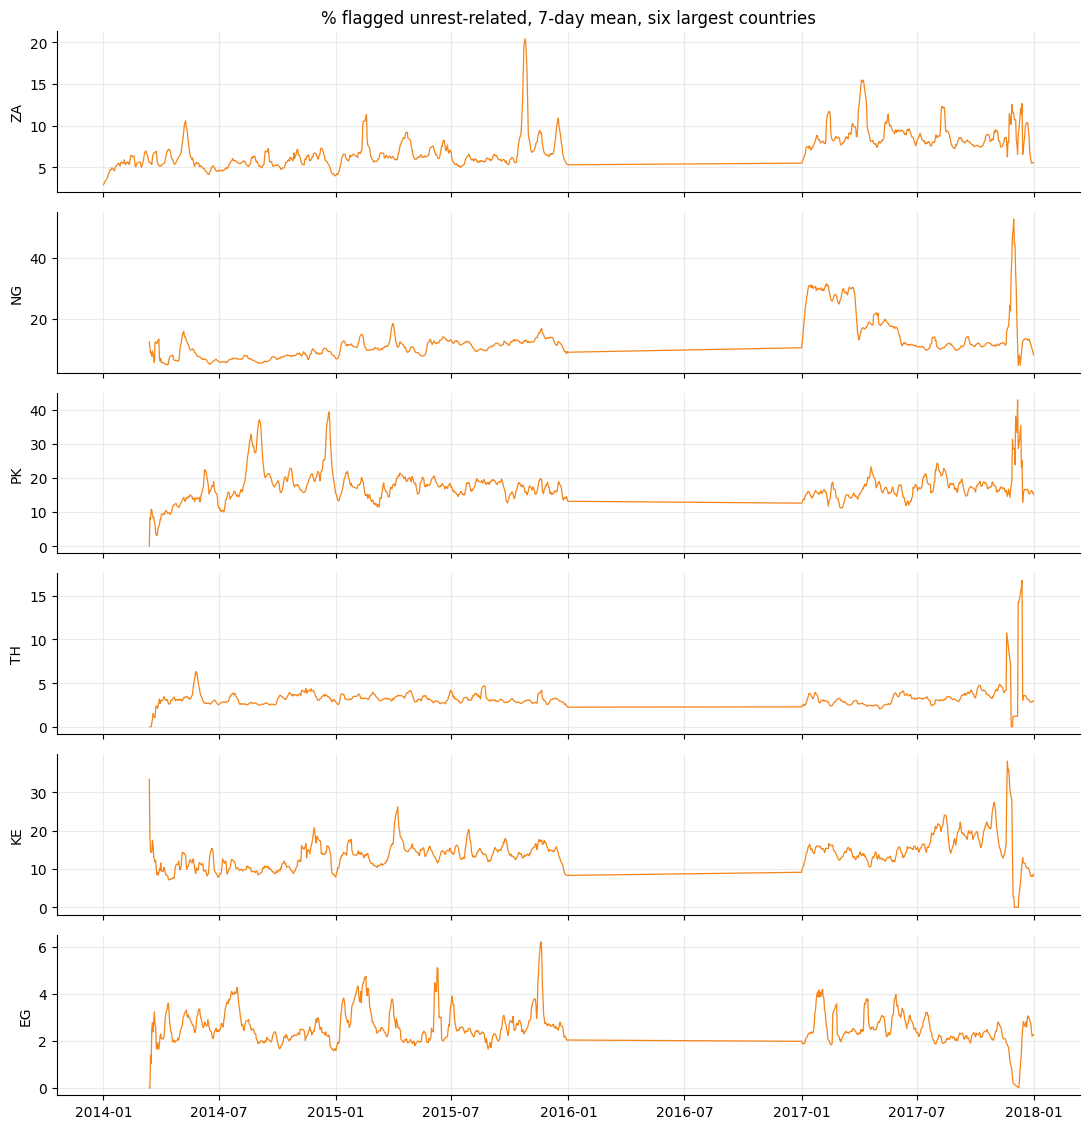

In [8]:
top5 = pc.head(6).index.tolist()
fig, axes = plt.subplots(len(top5), 1, figsize=(11, 1.9 * len(top5)), sharex=True)
for ax, c in zip(axes, top5):
    g = cd[cd["country"] == c].set_index("date")
    ax.plot(g.index, (g["n_related"] / g["n_tweets"]).rolling(7, min_periods=1).mean() * 100, lw=0.9, color="#f58518")
    ax.set_ylabel(c)
axes[0].set_title("% flagged unrest-related, 7-day mean, six largest countries"); plt.tight_layout(); plt.show()

## 4. Surge targets and the emergence task

`z_today = (related today - mean of previous 28 days) / (std of previous 28 days + 1)`. A **surge** is a day with `z_today >= 2` and at least 20 flagged tweets. The prediction task starts from a calm day (no surge today) and asks whether a surge occurs within the next 1, 3 or 7 days.

In [9]:
info = json.loads((SOC / "panel_info.json").read_text(encoding="utf-8"))
panel = pd.read_csv(SOC / "panel.csv.gz", parse_dates=["date"], keep_default_na=False, na_values=[""])
print("surge definition:", info["definition"])
print("val starts:", info["val_start"], "| test starts:", info["test_start"])
rows = []
for s, v in info["splits"].items():
    rows.append({"split": s, "rows": v["rows"], "from": v["date_min"], "to": v["date_max"], **{f"pos_rate_{k}": round(r, 4) for k, r in v["positive_rate"].items()}})
pd.DataFrame(rows)

surge definition: surge = z_today >= z_threshold and related tweets >= min_related; label is classifier-derived, not ground truth
val starts: 2017-02-23 | test starts: 2017-07-29


,split,rows,from,to,pos_rate_h1,pos_rate_h3,pos_rate_h7
0,train,26626,2014-01-29,2017-02-22,0.0292,0.0814,0.1703
1,val,6378,2017-02-23,2017-07-28,0.0235,0.0663,0.1446
2,test,6338,2017-07-29,2017-12-31,0.0245,0.0684,0.1457


surge days: 1,334 of 40,676 days with history (3.280%)


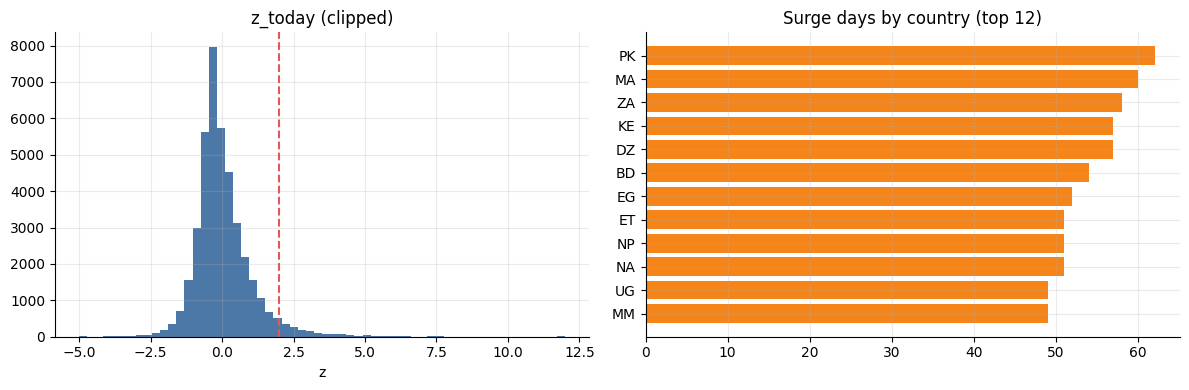

In [10]:
ok = panel[panel["history_ok"] == 1]
rate = ok.groupby("country")["surge"].agg(["mean", "sum"]).sort_values("sum", ascending=False)
print(f"surge days: {int(ok['surge'].sum()):,} of {len(ok):,} days with history ({ok['surge'].mean():.3%})")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(ok["z_today"].clip(-5, 12), bins=60, color="#4c78a8"); ax[0].axvline(2, color="#e45756", ls="--"); ax[0].set_title("z_today (clipped)"); ax[0].set_xlabel("z")
ax[1].barh(rate.head(12).index[::-1], rate.head(12)["sum"][::-1], color="#f58518"); ax[1].set_title("Surge days by country (top 12)")
plt.tight_layout(); plt.show()

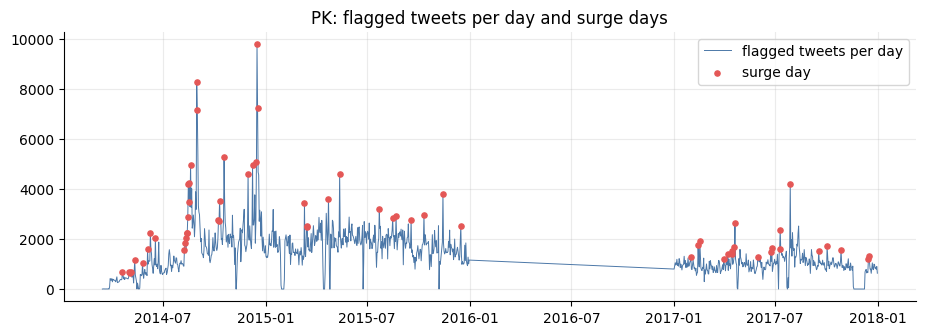

In [11]:
c = rate.index[0]
g = panel[(panel["country"] == c)].sort_values("date")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(g["date"], g["n_related"], lw=0.7, color="#4c78a8", label="flagged tweets per day")
s = g[g["surge"] == 1]
ax.scatter(s["date"], s["n_related"], color="#e45756", s=14, zorder=3, label="surge day")
ax.set_title(f"{c}: flagged tweets per day and surge days"); ax.legend(); plt.show()

## 5. Does a surge persist or predict the next one?

In [12]:
ok = panel[(panel["history_ok"] == 1)].copy()
tabs = []
for h in (1, 3, 7):
    t = ok.dropna(subset=[f"target_h{h}"])
    base_all = t[f"target_h{h}"].mean()
    after = t.loc[t["surge"] == 1, f"target_h{h}"].mean()
    calm = t.loc[t["surge"] == 0, f"target_h{h}"].mean()
    tabs.append({"horizon_days": h, "P(surge in next h | surge today)": round(after, 3), "P(... | calm today)": round(calm, 3), "ratio": round(after / calm, 2)})
pd.DataFrame(tabs)

,horizon_days,P(surge in next h | surge today),P(... | calm today),ratio
0,1,0.187,0.028,6.81
1,3,0.293,0.077,3.81
2,7,0.417,0.162,2.57


## 6. Model results (emergence of a surge from a calm day)

In [13]:
base_dirs = sorted(glob.glob(str(RES / "social_baselines_*")))
if base_dirs:
    m = json.loads(Path(base_dirs[-1], "metrics.json").read_text())["metrics"]
    rows = []
    for k, v in m.items():
        name, h = k.rsplit("_h", 1)
        t = v["test"]
        rows.append({"model": name, "horizon": int(h), "F1": t["f1"], "precision": t["precision"], "recall": t["recall"],
                     "PR-AUC": t["pr_auc"], "lift_over_base": t["pr_auc_lift_over_prevalence"], "ROC-AUC": t["roc_auc"], "base_rate": t["prevalence"]})
    base_df = pd.DataFrame(rows)
    print("baseline run:", Path(base_dirs[-1]).name)
    display_df = base_df.pivot(index="model", columns="horizon", values=["F1", "PR-AUC"]).round(3)
    display(display_df)
else:
    base_df = None
    print("no baseline results found - run scripts/social_train_baselines.py")

baseline run: social_baselines_20261117_185911


F1               PR-AUC              
horizon          1      3      7      1      3      7
model                                                
grad_boost   0.142  0.227  0.354  0.091  0.158  0.281
logistic     0.139  0.202  0.338  0.092  0.167  0.252
prevalence   0.000  0.000  0.000  0.024  0.068  0.146
recent_rule  0.059  0.149  0.281  0.033  0.082  0.154

In [14]:
seq_rows = []
for f in sorted(glob.glob(str(RES / "social_*_seed*" / "metrics.json"))):
    j = json.loads(Path(f).read_text())
    arch = j["args"]["arch"]; seed = int(j["args"]["seed"])
    for k, v in j["metrics"].items():
        h = int(k.rsplit("_h", 1)[1]); t = v["test"]
        seq_rows.append({"model": f"seq_{arch}", "seed": seed, "horizon": h, "F1": t["f1"], "PR-AUC": t["pr_auc"], "ROC-AUC": t["roc_auc"], "lift_over_base": t["pr_auc_lift_over_prevalence"]})
seq_df = pd.DataFrame(seq_rows)
if len(seq_df):
    agg = seq_df.groupby(["model", "horizon"])[["F1", "PR-AUC", "ROC-AUC"]].agg(["mean", "std"]).round(3)
    print("sequence models: mean and std over seeds", sorted(seq_df["seed"].unique()))
    display(agg)
else:
    print("no sequence-model results found - run scripts/social_train_sequence.py")

sequence models: mean and std over seeds [np.int64(42), np.int64(43), np.int64(44)]


F1        PR-AUC        ROC-AUC       
                          mean    std   mean    std    mean    std
model           horizon                                           
seq_gru         1        0.164  0.019  0.116  0.002   0.811  0.002
                3        0.245  0.018  0.170  0.008   0.759  0.005
                7        0.359  0.007  0.264  0.014   0.730  0.009
seq_transformer 1        0.147  0.015  0.087  0.002   0.768  0.009
                3        0.223  0.010  0.150  0.010   0.723  0.010
                7        0.338  0.020  0.243  0.011   0.705  0.014

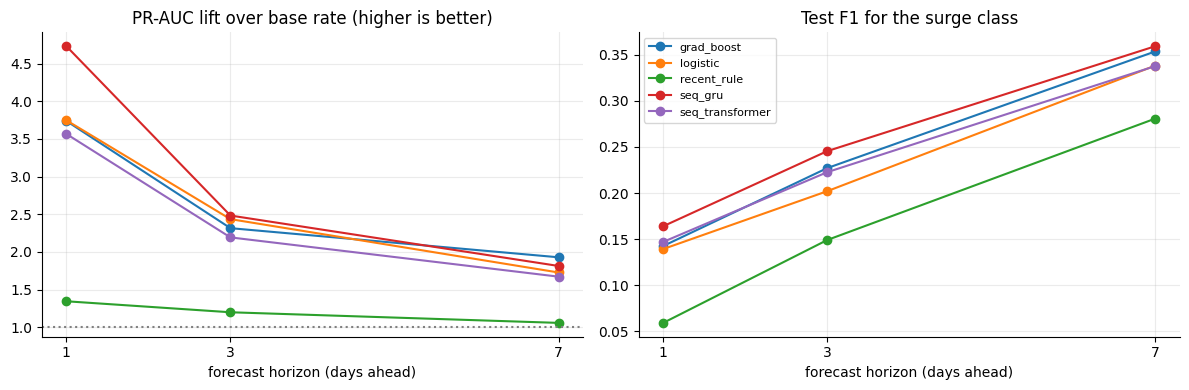

In [15]:
frames = []
if base_df is not None:
    frames.append(base_df[["model", "horizon", "PR-AUC", "lift_over_base", "F1"]])
if len(seq_df):
    frames.append(seq_df.groupby(["model", "horizon"], as_index=False)[["PR-AUC", "lift_over_base", "F1"]].mean())
if frames:
    allr = pd.concat(frames)
    allr = allr[allr["model"] != "prevalence"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for model, g in allr.groupby("model"):
        g = g.sort_values("horizon")
        ax[0].plot(g["horizon"], g["lift_over_base"], marker="o", label=model)
        ax[1].plot(g["horizon"], g["F1"], marker="o", label=model)
    ax[0].axhline(1, color="grey", ls=":"); ax[0].set_title("PR-AUC lift over base rate (higher is better)")
    ax[1].set_title("Test F1 for the surge class")
    for a in ax:
        a.set_xlabel("forecast horizon (days ahead)"); a.set_xticks([1, 3, 7])
    ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

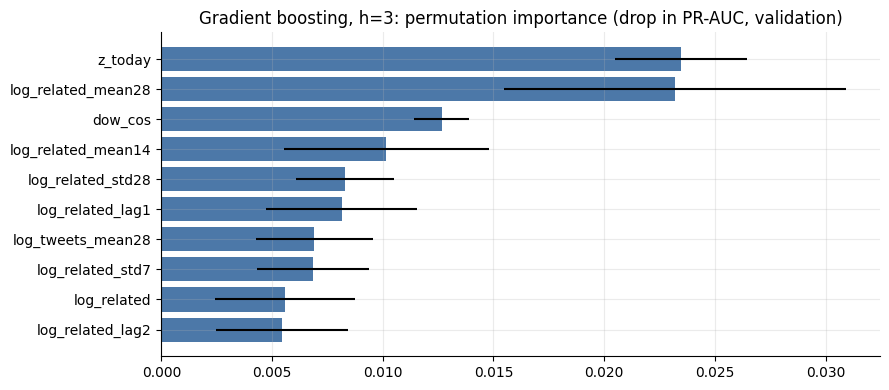

In [16]:
imp_files = sorted(glob.glob(str(RES / "social_baselines_*" / "feature_importance_h3.csv")))
if imp_files:
    imp = pd.read_csv(imp_files[-1]).head(10)
    plt.barh(imp["feature"][::-1], imp["importance_mean"][::-1], xerr=imp["importance_std"][::-1], color="#4c78a8")
    plt.title("Gradient boosting, h=3: permutation importance (drop in PR-AUC, validation)"); plt.tight_layout(); plt.show()

## 7. Findings and limitations

**What the data shows**
- 93,435,018 tweets across 42 countries, 2014, 2015 and 2017 (2016 is not in the files). 8.8% are flagged unrest-related; the share rises from 6.8% (2014) to 8.6% (2015) to 11.0% (2017).
- Volume is very uneven: South Africa alone has about a third of all tweets. Flagged share differs a lot by country (Pakistan 17.9%, Kenya 14.4%, Nigeria 13.4%, Egypt 2.6%, Thailand 3.1%), so a country's level mostly reflects the classifier and the sample, not how much unrest it has.
- Flagged share is higher Monday to Thursday (about 9.3-9.6%) than on weekends (about 7.6%). This is why day-of-week is a model feature.
- With the surge definition (z >= 2 against the previous 28 days and at least 20 flagged tweets), 1,334 of 40,676 usable country-days (3.3%) are surges.

**What the models show (test = Jul-Dec 2017, from a calm day)**
- Surges are partly predictable but not strongly. The best models reach PR-AUC lift of about 4.7x (1 day ahead), 2.5x (3 days) and 1.9x (7 days) over the base rate. F1 on the surge class is about 0.16, 0.25 and 0.36, because the base rate rises with the horizon (2.5%, 6.8%, 14.6%).
- Lift falls as the horizon grows, so lead time is short: the signal is mostly "activity is building now", not an early warning a week out.
- The GRU is best at 1 and 3 days. At 7 days gradient boosting is marginally ahead on PR-AUC (0.281 vs 0.264). The Transformer did not beat the GRU or logistic regression, and the gaps between the learned models are small next to the seed-to-seed spread, so no model is clearly better. A simple "recent activity" rule is near the base rate.

**Limitations**
- There is no tweet text, so this is signal forecasting, not event extraction. The transformer fine-tuning on ACLED text is a separate experiment.
- Labels come from a classifier. A surge means "the classifier flagged many more tweets than usual", not a verified protest or riot.
- There is no overlap with the ACLED India data (2018-2025), so nothing here has been checked against ground truth. Exporting ACLED for the same countries and 2014/2015/2017 would allow that.
- One chronological split, with a test period of about five months. Per-country results are not reported because most countries have few surges.
- Because 2016 is missing, the data is split into separate segments and the first 28 days of each segment (including early 2017) have no usable history and are left out.